# MedVision — Part C: Medical Text Classification

## Data Understanding, Exploratory Data Analysis and Data Cleaning

## 1. Import Libraries

In [1]:
import pandas as pd

## 2. Load Dataset

In [2]:
df = pd.read_csv("data/mtsamples.csv")

In [3]:
df.head()

,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


## 3. Dataset Overview

In [4]:
df.shape

(4999, 6)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Unnamed: 0         4999 non-null   int64
 1   description        4999 non-null   str  
 2   medical_specialty  4999 non-null   str  
 3   sample_name        4999 non-null   str  
 4   transcription      4966 non-null   str  
 5   keywords           3931 non-null   str  
dtypes: int64(1), str(5)
memory usage: 234.5 KB


In [6]:
df.isnull().sum()

Unnamed: 0              0
description             0
medical_specialty       0
sample_name             0
transcription          33
keywords             1068
dtype: int64

## 4. Target Variable Analysis

In [7]:
df["medical_specialty"].nunique()

40

In [8]:
df["medical_specialty"].value_counts()

medical_specialty
Surgery                          1103
Consult - History and Phy.        516
Cardiovascular / Pulmonary        372
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  230
Neurology                         223
SOAP / Chart / Progress Notes     166
Obstetrics / Gynecology           160
Urology                           158
Discharge Summary                 108
ENT - Otolaryngology               98
Neurosurgery                       94
Hematology - Oncology              90
Ophthalmology                      83
Nephrology                         81
Emergency Room Reports             75
Pediatrics - Neonatal              70
Pain Management                    62
Psychiatry / Psychology            53
Office Notes                       51
Podiatry                           47
Dermatology                        29
Dentistry                          27
Cosmetic / Plastic Surgery      

## 5. Duplicate Analysis

We investigate duplicate medical transcriptions to understand data quality before preprocessing.

We examine:
- Repeated transcription texts.
- Repeated transcription-specialty pairs.
- Fully duplicated records.

The goal is to identify potential data redundancy and label inconsistencies before model training.

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["transcription"].dropna().duplicated().sum()

np.int64(2609)

In [11]:
df["transcription"].nunique()

2357

In [12]:
df.groupby("transcription")["medical_specialty"].nunique().gt(1).sum()

np.int64(2148)

In [13]:
specialty_counts = df.groupby("transcription")["medical_specialty"].nunique()

In [14]:
specialty_counts.value_counts().sort_index()

medical_specialty
1     209
2    1725
3     388
4      34
5       1
Name: count, dtype: int64

In [15]:
conflicting_text = specialty_counts[specialty_counts > 1].index[0]

In [16]:
df.loc[
    df["transcription"] == conflicting_text,
    ["medical_specialty", "sample_name", "description"]
]

,medical_specialty,sample_name,description
874,Surgery,EGD With Photos & Biopsies.,EGD with photos and biopsies. This is a 75-y...
3577,Gastroenterology,EGD With Photos & Biopsies.,EGD with photos and biopsies. This is a 75-y...


In [17]:
df.duplicated(subset=["transcription", "medical_specialty"]).sum()

np.int64(27)

## 6. Exploratory Data Analysis (EDA)

In this section, we visualize the distribution of medical
specialties and explore important characteristics of the dataset.

In [18]:
import matplotlib.pyplot as plt

In [19]:
top_10 = df["medical_specialty"].value_counts().head(10)

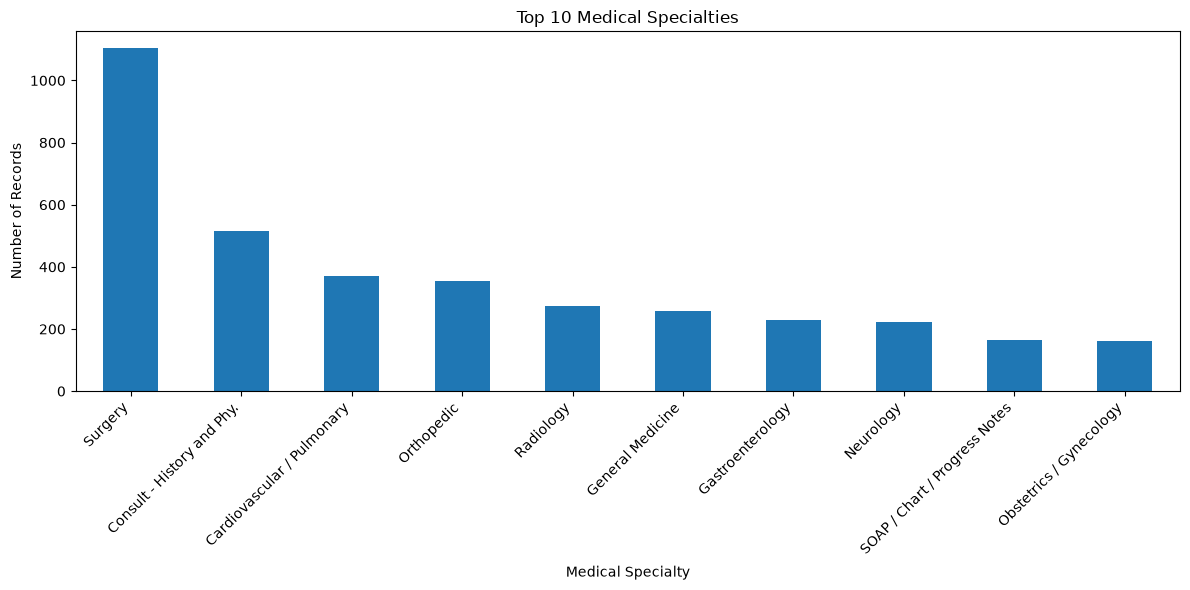

In [20]:
plt.figure(figsize=(12, 6))
top_10.plot(kind="bar")
plt.title("Top 10 Medical Specialties")
plt.xlabel("Medical Specialty")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 6.1 Text Length Analysis

We analyze the length of medical transcriptions to understand variations in document size before text preprocessing.

In [21]:
df["transcription"].dropna().str.split().str.len().describe()

count    4966.000000
mean      465.448852
std       316.386344
min         1.000000
25%       241.000000
50%       398.000000
75%       615.000000
max      3029.000000
Name: transcription, dtype: float64

In [22]:
text_lenghts = df["transcription"].dropna().str.split().str.len()

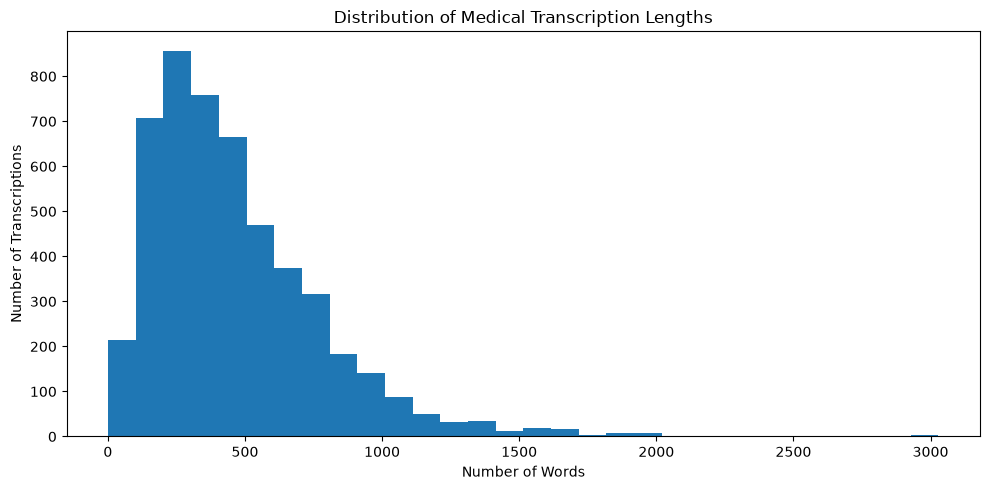

In [23]:
plt.figure(figsize=(10,5))
plt.hist(text_lenghts, bins=30)
plt.title("Distribution of Medical Transcription Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Transcriptions")
plt.tight_layout()
plt.show()

### 6.2 Inspecting Very Short Transcriptions

We inspect very short medical transcriptions to identify potentially incomplete or uninformative records.

In [24]:
df["transcription"].dropna().str.split().str.len().sort_values().head(10)

1949    1
1994    1
3306    1
1379    1
4658    1
1525    1
3579    2
4095    2
2206    2
2488    2
Name: transcription, dtype: int64

In [25]:
short_indices = df["transcription"].dropna().str.split().str.len().sort_values().head(10).index
df.loc[short_indices, ["transcription", "medical_specialty"]]

,transcription,medical_specialty
1949,"OPERATION:,",Pain Management
1994,"OPERATION:,",Pain Management
3306,"SUBJECTIVE:,",General Medicine
1379,"SUBJECTIVE:,",SOAP / Chart / Progress Notes
4658,"INDICATIONS:,",Cardiovascular / Pulmonary
1525,"INDICATIONS:,",Radiology
3579,"INDICATION: ,",Gastroenterology
4095,"CHIEF COMPLAINT:,",Consult - History and Phy.
2206,"CHIEF COMPLAINT:,",Orthopedic
2488,"CHIEF COMPLAINT:,",Office Notes


In [26]:
(text_lenghts < 10).sum()

np.int64(40)

In [27]:
short_texts = df.loc[
    text_lenghts[text_lenghts < 10].index,
    ["transcription", "medical_specialty"]
]

short_texts

,transcription,medical_specialty
24,"CHIEF COMPLAINT:,",Urology
318,"PREOPERATIVE DIAGNOSIS: ,1. Right carpal tun...",Surgery
606,"PREOPERATIVE DIAGNOSIS: ,Lateral epicondylitis.",Surgery
640,"PREOPERATIVE DIAGNOSIS:, Cholelithiasis; poss...",Surgery
643,"PREOPERATIVE DIAGNOSIS: , Biliary colic.",Surgery
872,"INDICATION: ,",Surgery
1379,"SUBJECTIVE:,",SOAP / Chart / Progress Notes
1522,"INDICATIONS: ,Chest pain.,STRESS TECHNIQUE:,",Radiology
1525,"INDICATIONS:,",Radiology
1949,"OPERATION:,",Pain Management


### Short Text Analysis — Findings

- 40 transcriptions contain fewer than 10 words.
- Some records contain only section headings, such as "OPERATION" or "CHIEF COMPLAINT".
- Other short records contain useful medical information.
- Short transcriptions should be reviewed before removal.
- Some short transcriptions are repeated across multiple records.
- Identical transcriptions may have the same or different medical specialty labels.

**Conclusion:** Text length alone is not sufficient to determine whether a transcription should be removed.

### 6.3 Class Imbalance Analysis

We examine the distribution of medical specialties to identify class imbalance before model training.

In [28]:
class_counts = df["medical_specialty"].value_counts()
class_counts.describe()

count      40.000000
mean      124.975000
std       197.667487
min         6.000000
25%        18.750000
50%        57.500000
75%       158.500000
max      1103.000000
Name: count, dtype: float64

### Class Imbalance — Findings

- The dataset contains 40 medical specialties.
- The number of records varies significantly across specialties.
- The mean is approximately 125 records per class, while the median is only 57.5.
- The largest class contains 1103 records, while the smallest contains only 6.
- This indicates substantial class imbalance.

**Conclusion:** Class imbalance should be considered during model training and evaluation. Accuracy alone may not adequately reflect performance across minority classes.

## 7. Data Cleaning

In this section, we prepare the dataset for text preprocessing and model training.

In [29]:
df_clean = df.copy()
print("Original shape: ",df.shape)
print("Working Copy shape: ", df_clean.shape)

Original shape:  (4999, 6)
Working Copy shape:  (4999, 6)



### 7.2 Handling Missing Transcriptions

Records with missing transcriptions are removed because they do not contain the input text required for classification.


In [30]:
df_clean = df_clean.dropna(subset=["transcription"])

print("Shape after cleaning:", df_clean.shape)


Shape after cleaning: (4966, 6)


### 7.3 Checking Empty or Whitespace-Only Transcriptions

We check whether any remaining transcriptions contain only whitespace or empty strings.

In [31]:
empty_texts = df_clean["transcription"].str.strip().eq("").sum()

empty_texts

np.int64(0)


### 7.4 Inspect Potentially Uninformative Transcriptions

Some short transcriptions contain only section headings, while others contain useful medical information.

We inspect these records before making any removal decisions.


In [32]:
short_mask = df_clean["transcription"].str.split().str.len() < 10 
short_records = df_clean.loc[
    short_mask,
    ["transcription","medical_specialty"]
]
print("Short records:", len(short_records))
display(short_records)


Short records: 40


,transcription,medical_specialty
24,"CHIEF COMPLAINT:,",Urology
318,"PREOPERATIVE DIAGNOSIS: ,1. Right carpal tun...",Surgery
606,"PREOPERATIVE DIAGNOSIS: ,Lateral epicondylitis.",Surgery
640,"PREOPERATIVE DIAGNOSIS:, Cholelithiasis; poss...",Surgery
643,"PREOPERATIVE DIAGNOSIS: , Biliary colic.",Surgery
872,"INDICATION: ,",Surgery
1379,"SUBJECTIVE:,",SOAP / Chart / Progress Notes
1522,"INDICATIONS: ,Chest pain.,STRESS TECHNIQUE:,",Radiology
1525,"INDICATIONS:,",Radiology
1949,"OPERATION:,",Pain Management


In [33]:
normalized_text = (
    short_records["transcription"].str.strip().str.upper().str.rstrip(" ::, ")
)

heading_mask = normalized_text.isin(headings)

print("Heading-records only: ",heading_mask.sum())
display(short_records.loc[heading_mask])

NameError: name 'headings' is not defined

In [ ]:
remaining_short = short_records.loc[~heading_mask]

print("Remaining short records:", len(remaining_short))
display(remaining_short)

Remaining short records: 24


,transcription,medical_specialty
318,"PREOPERATIVE DIAGNOSIS: ,1. Right carpal tun...",Surgery
606,"PREOPERATIVE DIAGNOSIS: ,Lateral epicondylitis.",Surgery
640,"PREOPERATIVE DIAGNOSIS:, Cholelithiasis; poss...",Surgery
643,"PREOPERATIVE DIAGNOSIS: , Biliary colic.",Surgery
1522,"INDICATIONS: ,Chest pain.,STRESS TECHNIQUE:,",Radiology
1957,"CHIEF COMPLAINT:, Right shoulder pain.,HISTOR...",Pain Management
1978,"OPERATION:, Lumbar epidural steroid injection...",Pain Management
2012,"CHIEF COMPLAINT:, Left wrist pain.,HISTORY OF...",Orthopedic
2047,"PREOPERATIVE DIAGNOSIS: ,1. Right carpal tun...",Orthopedic
2054,"CHIEF COMPLAINT:, Right shoulder pain.,HISTOR...",Orthopedic


In [ ]:
for index, text in remaining_short["transcription"].items():
    print(f"Index {index}: {repr(text)}")

Index 318: 'PREOPERATIVE DIAGNOSIS:  ,1.  Right carpal tunnel syndrome.,2.'
Index 606: 'PREOPERATIVE DIAGNOSIS:  ,Lateral epicondylitis.'
Index 640: 'PREOPERATIVE DIAGNOSIS:,  Cholelithiasis; possible choledocholithiasis.'
Index 643: 'PREOPERATIVE DIAGNOSIS: , Biliary colic.'
Index 1522: 'INDICATIONS:  ,Chest pain.,STRESS TECHNIQUE:,'
Index 1957: 'CHIEF COMPLAINT:,  Right shoulder pain.,HISTORY OF PRESENT PROBLEM:'
Index 1978: 'OPERATION:,  Lumbar epidural steroid injection, intralaminar approach, seated position.,ANESTHESIA:,'
Index 2012: 'CHIEF COMPLAINT:,  Left wrist pain.,HISTORY OF PRESENT PROBLEM:,'
Index 2047: 'PREOPERATIVE DIAGNOSIS:  ,1.  Right carpal tunnel syndrome.,2.'
Index 2054: 'CHIEF COMPLAINT:,  Right shoulder pain.,HISTORY OF PRESENT PROBLEM:'
Index 2102: 'XYZ, D.C.,60 Evergreen Place,Suite 902,East Orange, NJ  07018,Re:'
Index 2175: 'PREOPERATIVE DIAGNOSIS:  ,Lateral epicondylitis.'
Index 3065: 'XYZ, D.C.,60 Evergreen Place,Suite 902,East Orange, NJ  07018,Re:'
Index

In [ ]:
heading_indices = short_records.loc[heading_mask].index
administrative_indices = [2102, 3065]
indices_to_remove = heading_indices.tolist() + administrative_indices
df_clean = df_clean.drop(index=indices_to_remove)

print("Records to remove:", len(indices_to_remove))
print("Shape after removing uninformative texts:", df_clean.shape)

Records to remove: 18
Shape after removing uninformative texts: (4948, 6)


In [ ]:
duplicate_count = df_clean["transcription"].duplicated().sum()
print(duplicate_count)

2599


In [ ]:

duplicate_pairs = df_clean.duplicated(
    subset=["transcription", "medical_specialty"]
).sum()

print("Duplicate text-specialty pairs:", duplicate_pairs)


Duplicate text-specialty pairs: 1


In [ ]:
specialties_per_text = df_clean.groupby("transcription")["medical_specialty"].nunique()
conflicting_texts = (specialties_per_text > 1).sum()

print("Texts with multiple specialties:", conflicting_texts)

Texts with multiple specialties: 2141


In [ ]:
# Find transcriptions linked to multiple specialties
specialties_per_text = (
    df_clean.groupby("transcription")["medical_specialty"]
    .nunique()
)

conflicting_texts = specialties_per_text[
    specialties_per_text > 1
]

# Select one real example
example_text = conflicting_texts.index[0]

# Display every row containing this exact text
example_rows = df_clean.loc[
    df_clean["transcription"] == example_text,
    ["medical_specialty", "transcription"]
]

print("Original row indices:", example_rows.index.tolist())
print("Number of specialties:", example_rows["medical_specialty"].nunique())

display(example_rows)

Original row indices: [874, 3577]
Number of specialties: 2


,medical_specialty,transcription
874,Surgery,"1. Odynophagia.,2. Dysphagia.,3. Gastroesop..."
3577,Gastroenterology,"1. Odynophagia.,2. Dysphagia.,3. Gastroesop..."


## 8. Single-Label Dataset Preparation

For this project, we use a single-label classification approach, where each medical transcription is assigned one medical specialty.
The original cleaned dataset is preserved for reference.

In [ ]:
df_single = df_clean.drop_duplicates(
    subset=["transcription"],
    keep="first"
).copy()

print("Rows before deduplication:", len(df_clean))
print("Rows after deduplication:", len(df_single))
print("Rows removed:", len(df_clean) - len(df_single))

Rows before deduplication: 4948
Rows after deduplication: 2349
Rows removed: 2599


### Class Distribution After Single-Label Selection

We analyze the number of unique medical transcriptions assigned
to each specialty after deduplication.

The purpose is to identify underrepresented classes and assess
class imbalance before finalizing the dataset.

In [ ]:
specialty_counts = df_single["medical_specialty"].value_counts()
print("Number of specialties:", specialty_counts.size)

print("\nSpecialty distribution:")
display(specialty_counts)

print("\nSpecialties with fewer than 20 records:")
display(specialty_counts[specialty_counts < 20])

Number of specialties: 39

Specialty distribution:


medical_specialty
Surgery                          975
Radiology                        247
General Medicine                 157
Urology                          155
SOAP / Chart / Progress Notes    143
Neurology                         67
Consult - History and Phy.        55
Orthopedic                        53
Pediatrics - Neonatal             52
Psychiatry / Psychology           51
Pain Management                   44
Office Notes                      41
Hematology - Oncology             31
Gastroenterology                  31
Cardiovascular / Pulmonary        26
Obstetrics / Gynecology           26
Nephrology                        20
Sleep Medicine                    17
Emergency Room Reports            17
Discharge Summary                 17
ENT - Otolaryngology              16
Ophthalmology                     15
Bariatrics                        10
Podiatry                          10
Physical Medicine - Rehab         10
Speech - Language                  9
IME-QME-Work Comp et


Specialties with fewer than 20 records:


medical_specialty
Sleep Medicine                17
Emergency Room Reports        17
Discharge Summary             17
ENT - Otolaryngology          16
Ophthalmology                 15
Bariatrics                    10
Podiatry                      10
Physical Medicine - Rehab     10
Speech - Language              9
IME-QME-Work Comp etc.         9
Rheumatology                   8
Autopsy                        8
Letters                        7
Lab Medicine - Pathology       5
Hospice - Palliative Care      5
Dermatology                    4
Cosmetic / Plastic Surgery     2
Chiropractic                   2
Allergy / Immunology           1
Dentistry                      1
Neurosurgery                   1
Endocrinology                  1
Name: count, dtype: int64

In [ ]:
for min_count in [10, 20, 30, 50]:
    eligible_specialties = specialty_counts[specialty_counts >= min_count]

    print("Minimum records per specialty:", min_count)
    print("Specialties retained:", eligible_specialties.size)
    print("Records retained:", eligible_specialties.sum())
        

Minimum records per specialty: 10
Specialties retained: 25
Records retained: 2286
Minimum records per specialty: 20
Specialties retained: 17
Records retained: 2174
Minimum records per specialty: 30
Specialties retained: 14
Records retained: 2102
Minimum records per specialty: 50
Specialties retained: 10
Records retained: 1955


### Filtering Underrepresented Specialties

A minimum class size of 20 records was selected as a practical
baseline to exclude extremely underrepresented specialties.

This retains 17 medical specialties and 2,174 unique transcriptions.

The original single-label dataset is preserved. Class imbalance
will still be considered during model training and evaluation.

In [ ]:
min_count = 20

eligible_specialties = specialty_counts[
    specialty_counts >= min_count
].index

df_final = df_single[df_single["medical_specialty"].isin(eligible_specialties)].copy()

print("Final dataset shape:", df_final.shape)
print("Number of specialties:", df_final["medical_specialty"].nunique())
print("Unique transcriptions:", df_final["transcription"].nunique())

Final dataset shape: (2174, 6)
Number of specialties: 17
Unique transcriptions: 2174


### Final Data Validation

The filtered single-label dataset is validated before export.

We check for missing transcriptions, empty texts, duplicate
transcriptions, missing specialty labels, and the minimum
number of records per specialty.

In [ ]:
print("Total records: ", len(df_final))
print("Missing Transcriptions: ",df_final["transcription"].isna().sum())
print("Empty transcriptions: ",df_final["transcription"].str.strip().eq("").sum())
print("Duplicate transcriptions: ",df_final["transcription"].duplicated().sum())
print("Missing specialty labels: ", df_final["medical_specialty"].isna().sum())
print("Number of specialties: ",df_final["medical_specialty"].nunique())
print("Smallest class size: ",df_final["medical_specialty"].value_counts().min())

Total records:  2174
Missing Transcriptions:  0
Empty transcriptions:  0
Duplicate transcriptions:  0
Missing specialty labels:  0
Number of specialties:  17
Smallest class size:  20


### Final Class Distribution and Imbalance Review

We examine the class distribution of the filtered dataset
to identify dominant and underrepresented specialties.

Class imbalance will be documented and addressed during
model training and evaluation.

In [ ]:
final_counts = df_final["medical_specialty"].value_counts()

final_percentages = (
    df_final["medical_specialty"]
    .value_counts(normalize=True) * 100
)

balance_report = pd.DataFrame({
    "Count": final_counts,
    "Percentage": final_percentages.round(2)
})

display(balance_report)

,Count,Percentage
medical_specialty,,
Surgery,975,44.85
Radiology,247,11.36
General Medicine,157,7.22
Urology,155,7.13
SOAP / Chart / Progress Notes,143,6.58
Neurology,67,3.08
Consult - History and Phy.,55,2.53
Orthopedic,53,2.44
Pediatrics - Neonatal,52,2.39


## 9. Final Dataset Export

Only the input text and target label are selected for the
classification pipeline.

The complete cleaned DataFrame is preserved for reference.

In [ ]:

df_export = df_final[
    ["transcription", "medical_specialty"]
].copy()

print("Export dataset shape:", df_export.shape)

display(df_export.head())

Export dataset shape: (2174, 2)


,transcription,medical_specialty
3,"2-D M-MODE: , ,1. Left atrial enlargement wit...",Cardiovascular / Pulmonary
4,1. The left ventricular cavity size and wall ...,Cardiovascular / Pulmonary
7,"2-D ECHOCARDIOGRAM,Multiple views of the heart...",Cardiovascular / Pulmonary
9,"DESCRIPTION:,1. Normal cardiac chambers size....",Cardiovascular / Pulmonary
11,"2-D STUDY,1. Mild aortic stenosis, widely calc...",Cardiovascular / Pulmonary


In [ ]:
output_path = "data/medical_text_cleaned.csv"
df_export.to_csv(output_path, index=False)

print("Dataset saved successfully.")
print("File path:", output_path)

Dataset saved successfully.
File path: data/medical_text_cleaned.csv


In [ ]:
saved_df = pd.read_csv(output_path)

print("Saved dataset shape:", saved_df.shape)

print("Number of specialties:",
      saved_df["medical_specialty"].nunique())

print("Unique transcriptions:",
      saved_df["transcription"].nunique())

print("Matches exported dataset:",
      saved_df.equals(df_export.reset_index(drop=True)))

Saved dataset shape: (2174, 2)
Number of specialties: 17
Unique transcriptions: 2174
Matches exported dataset: True
